In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt

In [2]:
results = Path("..") / "results"
neuron = json.loads((results / "neuron_dev.json").read_text())
shallow = json.loads((results / "shallow_dev.json").read_text())

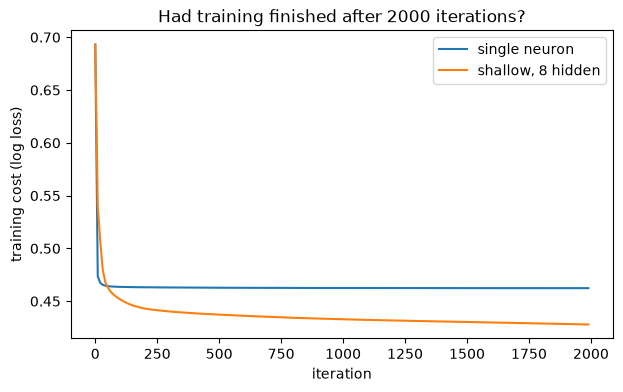

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, run in [("single neuron", neuron), ("shallow, 8 hidden", shallow)]:
    steps = [i * 10 for i in range(len(run["costs"]))]
    ax.plot(steps, run["costs"], label=name)
ax.set_xlabel("iteration")
ax.set_ylabel("training cost (log loss)")
ax.set_title("Had training finished after 2000 iterations?")
ax.legend()
plt.show()

In [4]:
for name, run in [("single neuron", neuron), ("shallow, 8 hidden", shallow)]:
    c = run["costs"]
    print(f"{name}: 1000 -> {c[100]:.5f}, 1500 -> {c[150]:.5f}, "
          f"1990 -> {c[199]:.5f}, last-500 drop = {c[150] - c[199]:.5f}")

single neuron: 1000 -> 0.46250, 1500 -> 0.46240, 1990 -> 0.46236, last-500 drop = 0.00004
shallow, 8 hidden: 1000 -> 0.43289, 1500 -> 0.43038, 1990 -> 0.42795, last-500 drop = 0.00243


## What the shallow network showed me

I kept everything the same as the single neuron (same data steps, learning
rate 0.5, 2000 iterations) and only added a hidden layer of 8 tanh neurons.

- Dev ROC-AUC went from 0.714 (my neuron and sklearn) to 0.762. PR-AUC, F1
  and log loss all got better too.
- At the 0.5 threshold it catches 356 of the 995 defaulters instead of 241,
  but it also wrongly flags 199 good customers instead of 106.
- Train cost (0.428) and dev log loss (0.440) are close, so it doesn't look
  like it's just memorising the training customers.
- It hadn't finished training. At the end the cost was still dropping about
  0.0024 every 500 iterations, while the neuron was only dropping 0.00004.
  So 0.762 comes from a network I stopped early, not its best.
- This is one seed and nothing is tuned yet. I haven't touched the test set.